# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Izra(Jamal) Abudiab, Mustafa Ali, Rashi Adhikari"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.

b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


a. PCA is a linear method, so it finds the directions where the data varies most and projects onto those. That works fine when the data's structure is basically flat, but a lot of real datasets (genomic data, images, text) have non-linear relationships that PCA just can't capture since it's limited to straight-line projections. t-SNE and UMAP were built for this problem. They can model non-linear structure and keep points that are similar in high-dimensional space close together in the 2D plot, even when that similarity isn't something a straight line could represent. That's why they tend to work better for visualizing messier, more complex data.

b. t-SNE is good at showing local structure. It pulls out tight, visually obvious clusters, which is probably why it's so popular for exploratory plots. The downsides are that it's slow (it scales as O(n²), so big datasets take a while), it's stochastic so results can change between runs unless you fix the random seed, and it tends to distort global structure, so the distance between two clusters in the plot isn't really meaningful.

UMAP improves on most of this. It's faster, scales better to bigger datasets, and does a better job of preserving both local and global structure because of how it's built using topological data analysis. It also handles a wider range of data types. In general, UMAP makes more sense when speed and the overall layout of the data matter, while t-SNE is still fine for smaller datasets where the goal is mainly to see tight clusters.

c. For t-SNE, the main hyperparameter is perplexity, which works like a stand-in for how many neighbors each point considers. A low perplexity (around 5-10) focuses on local structure and can reveal fine detail but might miss larger patterns. A high perplexity (around 30-50) leans more global and shows broader trends, though it can blur local detail.

For UMAP, the two main hyperparameters are n_neighbors and min_dist. n_neighbors controls how large a neighborhood each point considers, so a higher value captures more global structure while a lower value keeps things local. min_dist controls how tightly points get packed together in the output, where a smaller value produces tighter clusters and a larger value spreads points out more to preserve global relationships.

## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [7]:
# YOUR CODE HERE
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load Palmer Penguins dataset (same source used in the UMAP documentation)
penguins = pd.read_csv(
    "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/master/inst/extdata/penguins.csv"
)

# Drop rows with missing values in the features we need
penguins = penguins.dropna(subset=[
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"
])

# Select the numerical features
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = penguins[features]

# Keep species around for coloring plots later (needed in part 2b)
species = penguins["species"]

# Standardize: zero mean, unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape) 
X.head()

(342, 4)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


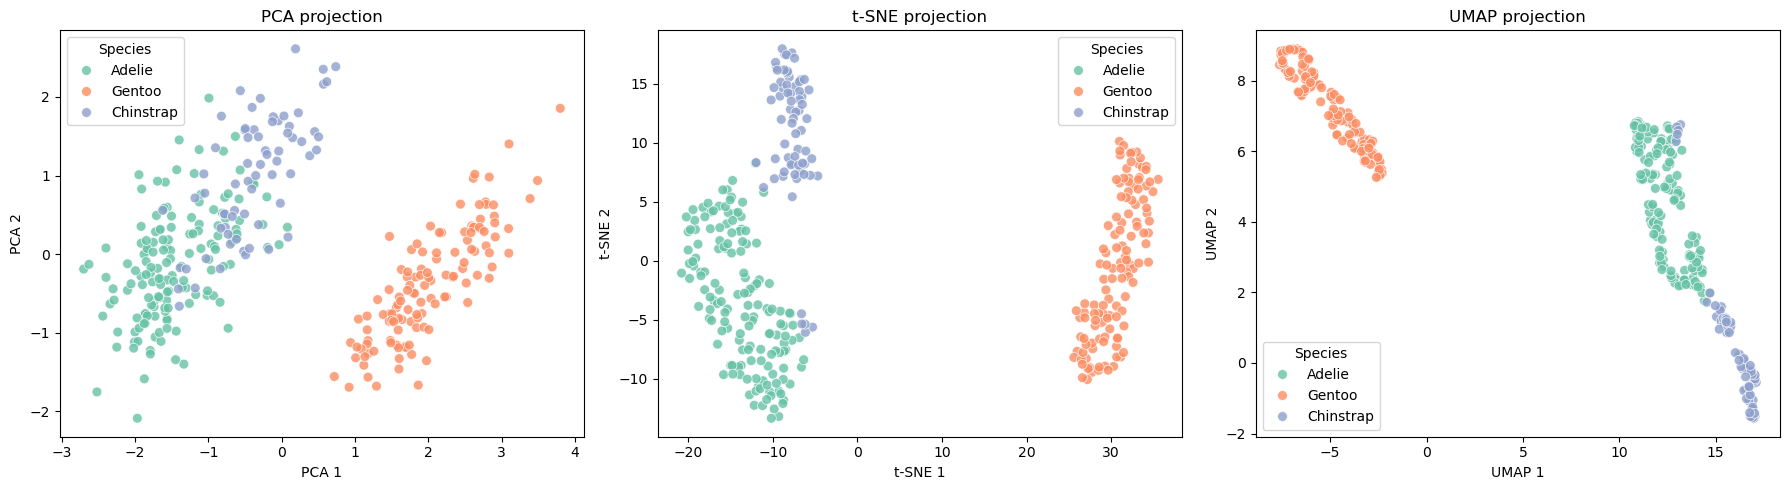

In [8]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

pca_emb = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
tsne_emb = TSNE(n_components=2, random_state=42).fit_transform(X_scaled)
umap_emb = umap.UMAP(n_components=2, random_state=42).fit_transform(X_scaled)

embeddings = {
    "PCA": pca_emb,
    "t-SNE": tsne_emb,
    "UMAP": umap_emb,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, emb) in zip(axes, embeddings.items()):
    sns.scatterplot(
        x=emb[:, 0], y=emb[:, 1], hue=species.values, palette="Set2", s=50, alpha=0.8, ax=ax
    )
    ax.set_title(f"{name} projection")
    ax.set_xlabel(f"{name} 1")
    ax.set_ylabel(f"{name} 2")
    ax.legend(title="Species")

plt.tight_layout()
plt.show()

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


t-SNE  and UMAP have the biggest differences and are the most visually separable clusters. There is a lot of overlap in PCA, and none really in UMAP and T-SNE. The borders are very close for those two, but no real obvious or significant overlap. t-SNE and UMAP have good use cases when trying to visualize the non-linear separation between the classes in a more powerful way than PCA. PCA captures variance in linear directions, but t-SNE and UMAP are great at preserving local structure and global structure in non-linear scenarios in PCA.

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

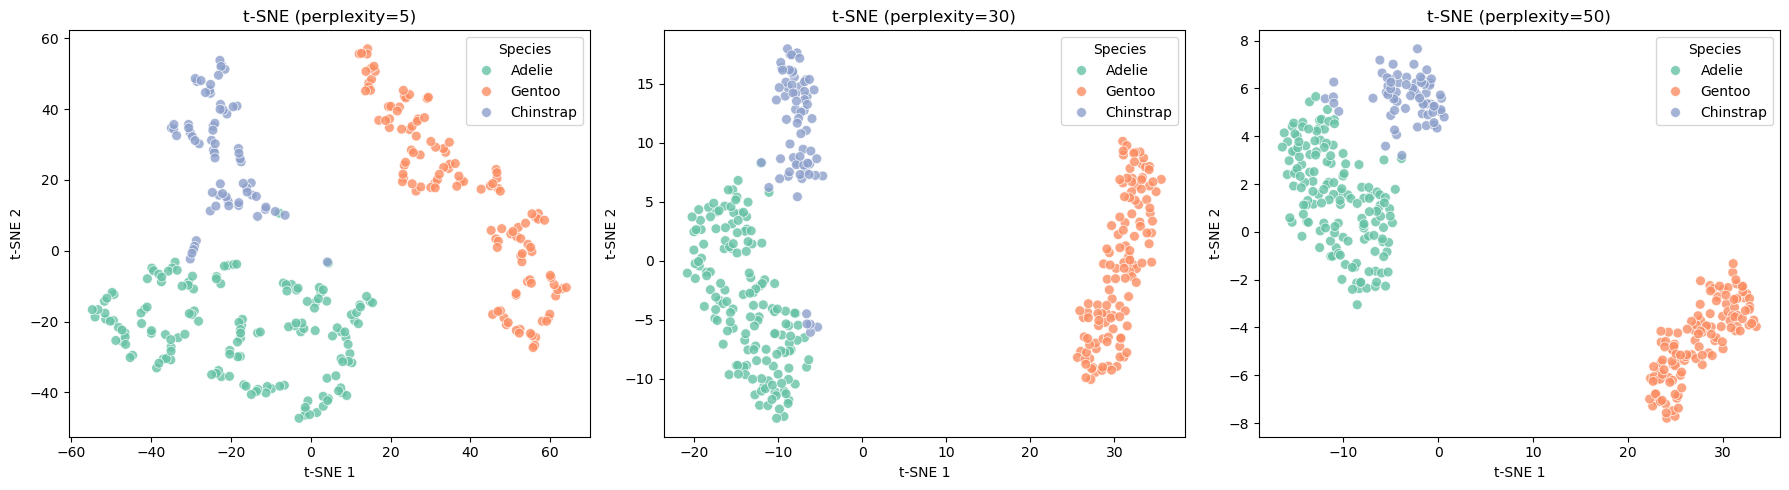

c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\jabud\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for paralle

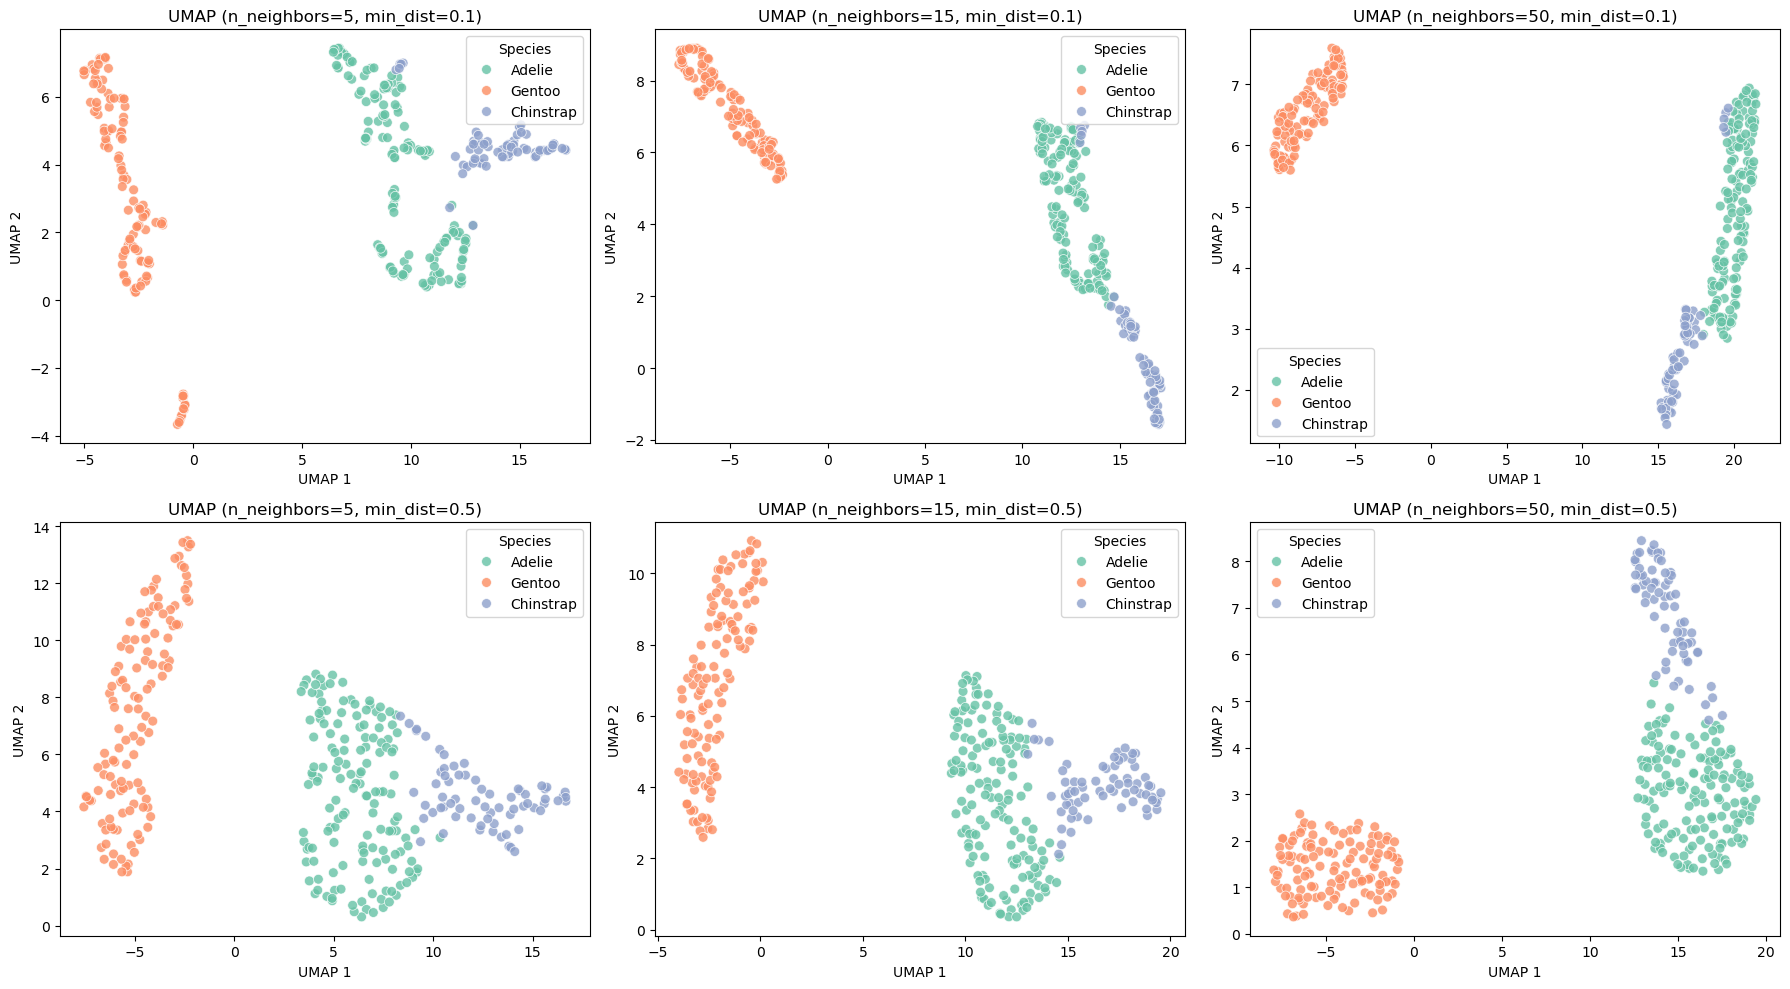

In [9]:
# YOUR CODE HERE
perplexities = [5, 30, 50]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, perp in zip(axes, perplexities):
    emb = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X_scaled)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=species.values, palette="Set2", s=50, alpha=0.8, ax=ax)
    ax.set_title(f"t-SNE (perplexity={perp})")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend(title="Species")
plt.tight_layout()
plt.show()

n_neighbors_list = [5, 15, 50]
min_dist_list = [0.1, 0.5]

fig, axes = plt.subplots(len(min_dist_list), len(n_neighbors_list), figsize=(18, 10))
for i, md in enumerate(min_dist_list):
    for j, nn in enumerate(n_neighbors_list):
        ax = axes[i, j]
        emb = umap.UMAP(n_components=2, n_neighbors=nn, min_dist=md,
                        random_state=42).fit_transform(X_scaled)
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=species.values,
                        palette="Set2", s=50, alpha=0.8, ax=ax)
        ax.set_title(f"UMAP (n_neighbors={nn}, min_dist={md})")
        ax.set_xlabel("UMAP 1")
        ax.set_ylabel("UMAP 2")
        ax.legend(title="Species")
plt.tight_layout()
plt.show()

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

With t-SNE with Perplexity seems to bring the groups together, and blur the line, seemingly loosing some of the perplexity. But distance between the groups shrinks as perplexity grows.

UMAP instead gets closer together locally when the n_neighbors increases, but globally we see Adelie and Chinstrap get closer together globally. This is the case with minimum distance 0.1. But when we increased the distance, I'd say while the groups felt less cohesive locally, globally they seemed more cleanly separated. As n_neighbors increases with min dist 0.5 the groups stays separate, and while Adelie and chinstrap are close to each other, they are notably not super close to each other, and you can make a mental line between the two sides.

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

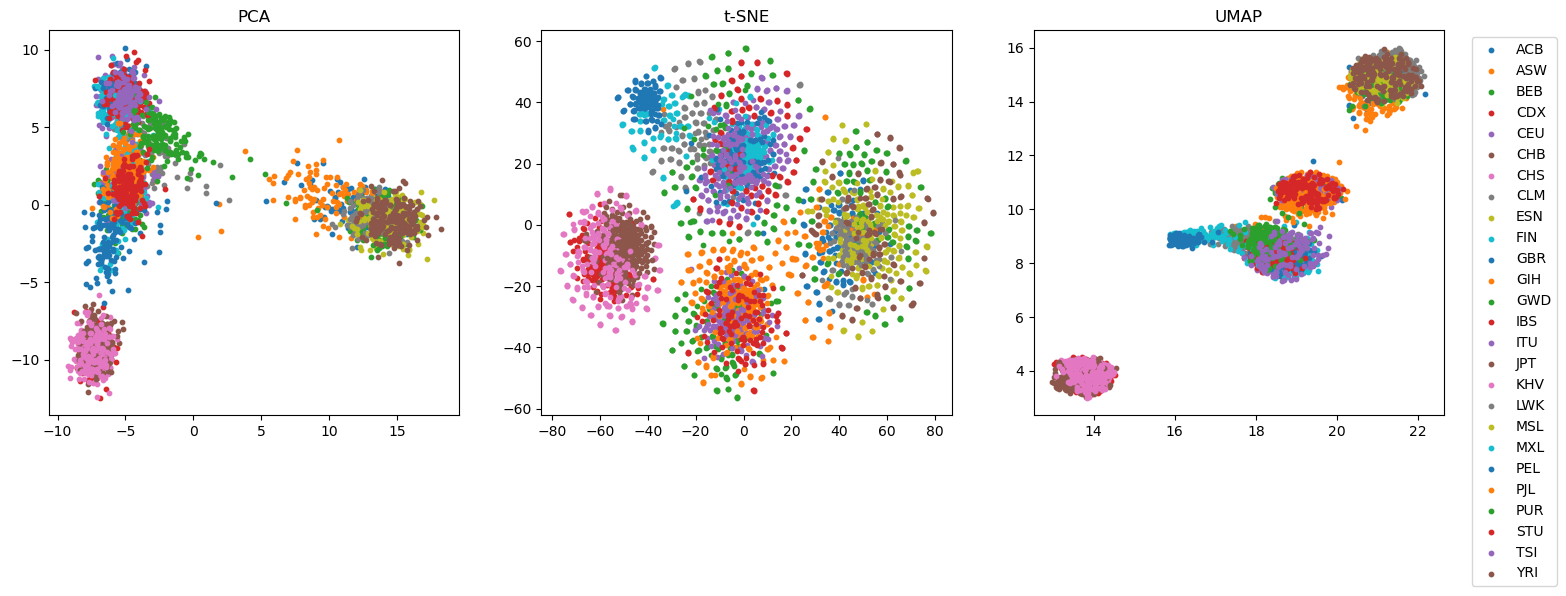

In [10]:
#a) 
import numpy as np

X = np.load("genome_data_lab3.npy")
population_labels = np.loadtxt("population_labels_lab3.txt", dtype=str)

#b) 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#c)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

X_pca = PCA(n_components=2).fit_transform(X_scaled)
X_tsne = TSNE(n_components=2).fit_transform(X_scaled)
X_umap = umap.UMAP(n_components=2).fit_transform(X_scaled)

#d) 
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, data, title in zip(axes, [X_pca, X_tsne, X_umap], ["PCA", "t-SNE", "UMAP"]):
    for pop in np.unique(population_labels):
        mask = population_labels == pop
        ax.scatter(data[mask, 0], data[mask, 1], label=pop, s=10)
    ax.set_title(title)
axes[2].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

**e.**

1. PCA demonstrates broader population clusters but has more overlap, as it uses a linear method that maximizes the variance preserved. t-SNE separates the groups better than PCA but still contains overlapping structures. Finally, UMAP shows the clearest separation of clusters, with about five distinct clusters. This is because UMAP is able to capture nonlinear relationships while preserving local and some global structure.

2. Reducing to 25 PCA components removes some of the noise and makes t-SNE and UMAP computationally faster. This can also create clearer and more compact clusters. However, some meaningful genetic information may be lost when lower-variance components are removed.

3. PCA is the most interpretable and computationally efficient because it preserves the major directions of variance and global structure. However, PCA also has weaker cluster separation, making clusters harder to distinguish visually. t-SNE preserves local structure and separates the groups better, but is slower and less interpretable globally. UMAP offers a good balance between the two by providing clearer clusters, faster computation, and preserving some global structure. However, the distances between clusters are still hard to interpret.


## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

1. One challenge that we faced was making sure everyone had the correct Python libraries installed. For example, the UMAP section required an additional installation, which caused errors affecting everyone’s work. This slowed down our progress and created errors. On top of that, we didn’t communicate clearly about who would be working on the lab over break, so a lot of it ended up getting pushed to the last second, which gave us less time to catch and fix the installation issues when they came up.

2. For the next lab, we plan to check the required libraries to make sure everyone has the same setup to avoid technical issues. We also plan to check in with each other about availability over breaks or busy weeks so we can plan a more realistic timeline instead of leaving things until the last minute.